# Analisis Pola Pembelian Pelanggan Toko Roti Menggunakan Perbandingan Algoritma Apriori, FP-Growth, dan ECLAT (From Scratch)

**Mata Kuliah:** Data Mining — Team-Based Project
**Teknik:** Market Basket Analysis (Association Rule Mining)
**Pustaka utama:** `pandas`, `numpy`, `matplotlib`, `seaborn` (algoritma Apriori, FP-Growth, ECLAT, dan pembangkitan aturan diimplementasikan *from scratch* tanpa library mining)

**Alur notebook** (mengikuti tahapan TBP):

1. Problem Definition
2. Data Collection
3. Data Preprocessing
4. Exploratory Data Analysis (EDA)
5. Modeling (Apriori vs FP-Growth vs ECLAT — *from scratch*)
6. Evaluation & Insight Bisnis
7. Persiapan Deployment (ekspor aturan untuk dashboard web HTML/CSS/JS)

## 1. Problem Definition

**Latar belakang.** Toko roti ingin memahami barang apa saja yang sering dibeli bersamaan agar dapat menyusun paket bundling, tata letak produk, dan promosi yang lebih tepat.

**Tujuan.**
1. Menemukan pola pembelian pelanggan berupa *association rules* `{A} → {B}`.
2. Membandingkan **Apriori**, **FP-Growth**, dan **ECLAT** dari sisi waktu eksekusi, jumlah *frequent itemset*, dan jumlah aturan.
3. Menerjemahkan aturan terbaik (berdasarkan *lift*) menjadi rekomendasi bisnis.

**Metrik yang digunakan.**

| Metrik | Makna |
|---|---|
| Support | Proporsi transaksi yang memuat itemset tersebut |
| Confidence | Peluang B dibeli jika A sudah dibeli, `P(B \| A)` |
| Lift | Seberapa kuat A dan B berasosiasi dibanding kebetulan. Lift > 1 berarti asosiasi positif |

## 2. Data Collection

**Sumber:** dataset *Bread Basket* (Kaggle), berisi data transaksi sebuah toko roti/kafe.

| Kolom | Deskripsi |
|---|---|
| `Transaction` | ID transaksi (satu transaksi bisa terdiri dari beberapa baris) |
| `Item` | Nama barang yang dibeli |
| `date_time` | Waktu transaksi (format `dd-mm-yyyy hh:mm`) |
| `period_day` | Periode hari: morning, afternoon, evening, night |
| `weekday_weekend` | Penanda hari kerja atau akhir pekan |

Setiap baris mewakili **satu item** dalam satu transaksi.

In [1]:
import time
import warnings
import itertools
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

DATA_PATH = "bread_basket.csv"   # ubah jika lokasi file berbeda
RANDOM_STATE = 42

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print("Ukuran data (baris, kolom):", df_raw.shape)
df_raw.head(10)

Ukuran data (baris, kolom): (20507, 5)


,Transaction,Item,date_time,period_day,weekday_weekend
0,1,Bread,30-10-2016 09:58,morning,weekend
1,2,Scandinavian,30-10-2016 10:05,morning,weekend
2,2,Scandinavian,30-10-2016 10:05,morning,weekend
3,3,Hot chocolate,30-10-2016 10:07,morning,weekend
4,3,Jam,30-10-2016 10:07,morning,weekend
5,3,Cookies,30-10-2016 10:07,morning,weekend
6,4,Muffin,30-10-2016 10:08,morning,weekend
7,5,Coffee,30-10-2016 10:13,morning,weekend
8,5,Pastry,30-10-2016 10:13,morning,weekend
9,5,Bread,30-10-2016 10:13,morning,weekend


In [3]:
df_raw.info()
print()
print("Jumlah transaksi unik :", df_raw["Transaction"].nunique())
print("Jumlah item unik      :", df_raw["Item"].nunique())
print("Baris duplikat penuh  :", df_raw.duplicated().sum())
print("Missing value per kolom:")
print(df_raw.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 20507 entries, 0 to 20506
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Transaction      20507 non-null  int64
 1   Item             20507 non-null  str  
 2   date_time        20507 non-null  str  
 3   period_day       20507 non-null  str  
 4   weekday_weekend  20507 non-null  str  
dtypes: int64(1), str(4)
memory usage: 801.2 KB

Jumlah transaksi unik : 9465
Jumlah item unik      : 94
Baris duplikat penuh  : 1620
Missing value per kolom:
Transaction        0
Item               0
date_time          0
period_day         0
weekday_weekend    0
dtype: int64


## 3. Data Preprocessing

Langkah yang dilakukan:

1. Menyamakan penulisan nama item (spasi berlebih, huruf besar/kecil).
2. Membuang item non-produk (bukan barang yang relevan untuk analisis keranjang, misalnya `Adjustment`, `Gift voucher`, merchandise).
3. Membuang duplikat item dalam satu transaksi.
4. Mengubah ke format transaksi (list item per transaksi).
5. Membuang transaksi dengan 1 item, karena tidak dapat menghasilkan aturan.
6. Mengubah ke bentuk *one-hot* (True/False per item).

In [4]:
df = df_raw.copy()

# 1) Samakan penulisan nama item
df["Item"] = (
    df["Item"]
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.lower()
    .str.capitalize()
)
print("Jumlah item unik setelah normalisasi:", df["Item"].nunique())

# 2) Buang item non-produk
#    Daftar ini bisa disesuaikan oleh tim setelah meninjau daftar item di bawah.
NON_PRODUCT = [
    "Adjustment", "Gift voucher", "Postcard", "Tshirt", "Valentine's card",
    "Nomad bag", "Basket", "Fairy doors", "Art tray", "Christmas common",
    "Mortimer", "Bowl nic pitt",
]
print("\nDaftar semua item (untuk ditinjau):")
print(sorted(df["Item"].unique()))

n_before = len(df)
df = df[~df["Item"].isin(NON_PRODUCT)]
print(f"\nBaris dibuang (non-produk): {n_before - len(df)}")

Jumlah item unik setelah normalisasi: 94

Daftar semua item (untuk ditinjau):
['Adjustment', 'Afternoon with the baker', 'Alfajores', 'Argentina night', 'Art tray', 'Bacon', 'Baguette', 'Bakewell', 'Bare popcorn', 'Basket', 'Bowl nic pitt', 'Bread', 'Bread pudding', 'Brioche and salami', 'Brownie', 'Cake', 'Caramel bites', 'Cherry me dried fruit', 'Chicken sand', 'Chicken stew', 'Chimichurri oil', 'Chocolates', 'Christmas common', 'Coffee', 'Coffee granules', 'Coke', 'Cookies', 'Crepes', 'Crisps', 'Drinking chocolate spoons', 'Duck egg', 'Dulce de leche', 'Eggs', "Ella's kitchen pouches", 'Empanadas', 'Extra salami or feta', 'Fairy doors', 'Farm house', 'Focaccia', 'Frittata', 'Fudge', 'Gift voucher', 'Gingerbread syrup', 'Granola', 'Hack the stack', 'Half slice monster', 'Hearty & seasonal', 'Honey', 'Hot chocolate', 'Jam', 'Jammie dodgers', 'Juice', 'Keeping it local', 'Kids biscuit', 'Lemon and coconut', 'Medialuna', 'Mighty protein', 'Mineral water', 'Mortimer', 'Muesli', 'Muffin',

In [5]:
# 3) Buang duplikat item dalam satu transaksi
n_before = len(df)
df = df.drop_duplicates(subset=["Transaction", "Item"])
print(f"Baris dibuang (duplikat dalam transaksi): {n_before - len(df)}")

# 4) Format transaksi: list item per transaksi
transactions = df.groupby("Transaction")["Item"].apply(list)
print("\nJumlah transaksi sebelum filter ukuran:", len(transactions))

# 5) Buang transaksi 1 item
size = transactions.apply(len)
print(f"Transaksi 1 item : {(size == 1).sum()} ({(size == 1).mean():.1%})")
transactions_multi = transactions[size >= 2]
print("Transaksi >= 2 item (dipakai untuk mining):", len(transactions_multi))

transactions_multi.head()

Baris dibuang (duplikat dalam transaksi): 1620

Jumlah transaksi sebelum filter ukuran: 9423
Transaksi 1 item : 3928 (41.7%)
Transaksi >= 2 item (dipakai untuk mining): 5495


Transaction
3       [Hot chocolate, Jam, Cookies]
5             [Coffee, Pastry, Bread]
6         [Medialuna, Pastry, Muffin]
7    [Medialuna, Pastry, Coffee, Tea]
8                     [Pastry, Bread]
Name: Item, dtype: object

In [6]:
# 6) One-hot encoding (from scratch dengan Python & pandas)
all_items = sorted({item for trx in transactions_multi for item in trx})
item_to_idx = {item: idx for idx, item in enumerate(all_items)}

onehot = np.zeros((len(transactions_multi), len(all_items)), dtype=bool)
for row_idx, trx in enumerate(transactions_multi):
    for item in trx:
        onehot[row_idx, item_to_idx[item]] = True

basket = pd.DataFrame(onehot, columns=all_items, index=transactions_multi.index)

print("Bentuk matriks one-hot (transaksi x item):", basket.shape)
basket.iloc[:5, :8]

Bentuk matriks one-hot (transaksi x item): (5495, 81)


,Afternoon with the baker,Alfajores,Argentina night,Bacon,Baguette,Bakewell,Bare popcorn,Bread
Transaction,,,,,,,,
3,False,False,False,False,False,False,False,False
5,False,False,False,False,False,False,False,True
6,False,False,False,False,False,False,False,False
7,False,False,False,False,False,False,False,False
8,False,False,False,False,False,False,False,True


## 4. Exploratory Data Analysis (EDA)

EDA dilakukan pada data **setelah dibersihkan** (seluruh transaksi, termasuk yang hanya 1 item) agar gambaran penjualan toko tetap utuh. Matriks `basket` hanya dipakai untuk mining.

In [7]:
# Siapkan kolom waktu
df["date_time"] = pd.to_datetime(df["date_time"], format="%d-%m-%Y %H:%M")
df["hour"] = df["date_time"].dt.hour
df["day_name"] = df["date_time"].dt.day_name()
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

print("Rentang tanggal:", df["date_time"].min(), "s.d.", df["date_time"].max())

Rentang tanggal: 2016-10-30 09:58:00 s.d. 2017-04-09 15:04:00


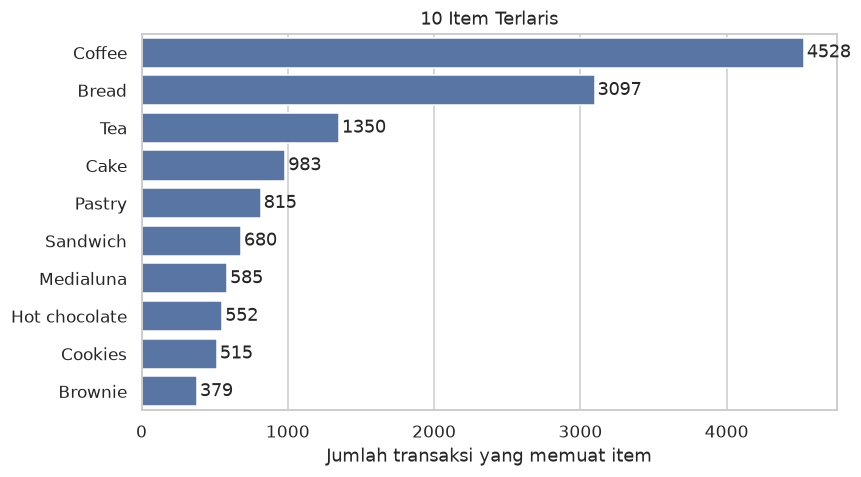

In [8]:
# 4a) Item terlaris
top_n = 10
item_counts = df["Item"].value_counts()

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=item_counts.head(top_n).values, y=item_counts.head(top_n).index, ax=ax)
ax.set_title(f"{top_n} Item Terlaris")
ax.set_xlabel("Jumlah transaksi yang memuat item")
ax.set_ylabel("")
for p in ax.patches:
    ax.text(p.get_width() + 20, p.get_y() + p.get_height() / 2, int(p.get_width()), va="center")
plt.tight_layout()
plt.show()

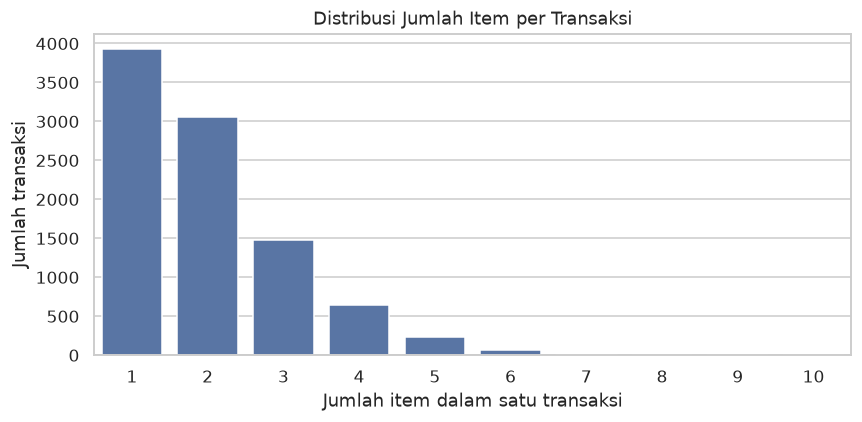

count    9423.00
mean        1.99
std         1.12
min         1.00
25%         1.00
50%         2.00
75%         3.00
max        10.00
Name: Item, dtype: float64


In [9]:
# 4b) Distribusi jumlah item per transaksi
items_per_trx = df.groupby("Transaction")["Item"].nunique()

fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(x=items_per_trx, ax=ax)
ax.set_title("Distribusi Jumlah Item per Transaksi")
ax.set_xlabel("Jumlah item dalam satu transaksi")
ax.set_ylabel("Jumlah transaksi")
plt.tight_layout()
plt.show()

print(items_per_trx.describe().round(2))

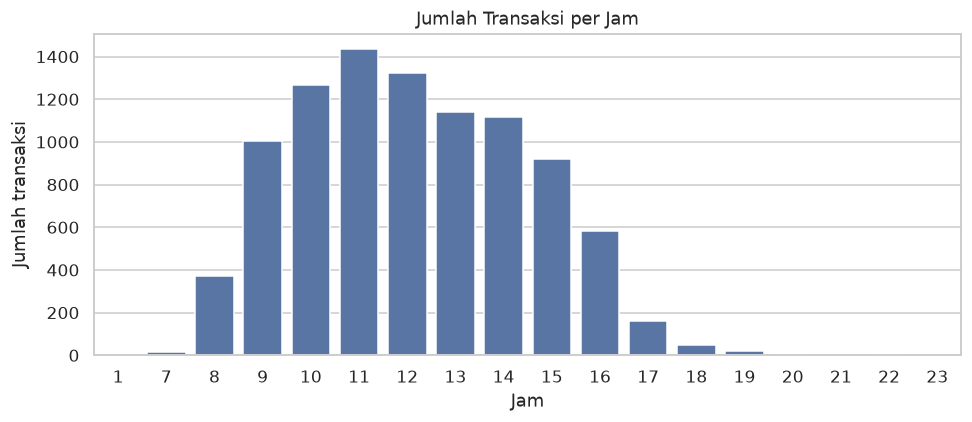

In [10]:
# 4c) Pola per jam
trx_time = df.drop_duplicates("Transaction")[["Transaction", "hour", "day_name", "period_day", "weekday_weekend"]]

fig, ax = plt.subplots(figsize=(9, 4))
sns.countplot(x="hour", data=trx_time, ax=ax, color=sns.color_palette()[0])
ax.set_title("Jumlah Transaksi per Jam")
ax.set_xlabel("Jam")
ax.set_ylabel("Jumlah transaksi")
plt.tight_layout()
plt.show()

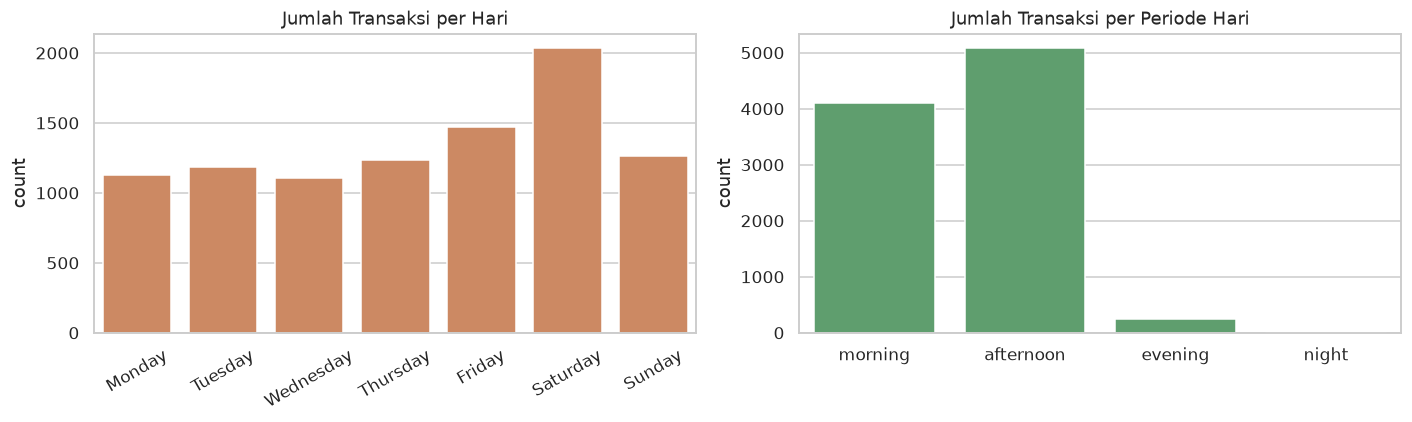

In [11]:
# 4d) Pola per hari dan periode
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(x="day_name", data=trx_time, order=day_order, ax=axes[0], color=sns.color_palette()[1])
axes[0].set_title("Jumlah Transaksi per Hari")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=30)

period_order = ["morning", "afternoon", "evening", "night"]
sns.countplot(x="period_day", data=trx_time, order=period_order, ax=axes[1], color=sns.color_palette()[2])
axes[1].set_title("Jumlah Transaksi per Periode Hari")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

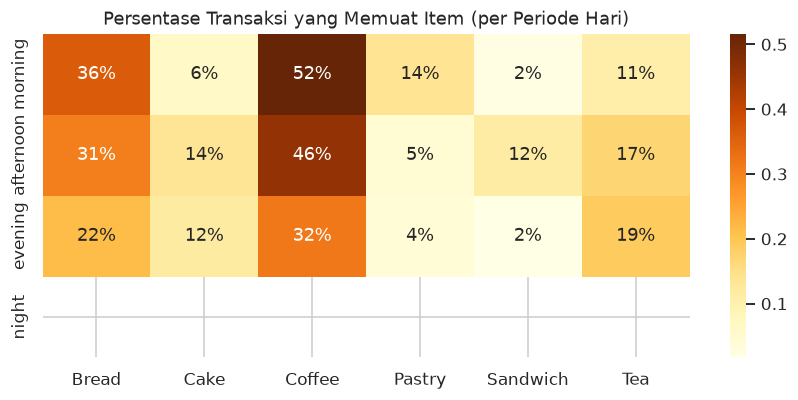

In [12]:
# 4e) Item terlaris berdasarkan periode hari (proporsi dalam periode)
top_items = item_counts.head(6).index
tmp = df[df["Item"].isin(top_items)].merge(
    trx_time[["Transaction"]], on="Transaction"
)
pivot = (
    tmp.groupby(["period_day", "Item"])["Transaction"].nunique().unstack(fill_value=0)
    .reindex(period_order)
)
pivot_pct = pivot.div(trx_time.groupby("period_day")["Transaction"].nunique().reindex(period_order), axis=0)

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.heatmap(pivot_pct, annot=True, fmt=".0%", cmap="YlOrBr", ax=ax)
ax.set_title("Persentase Transaksi yang Memuat Item (per Periode Hari)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 5. Modeling: Apriori vs FP-Growth vs ECLAT (From Scratch)

Ketiga algoritma diimplementasikan **from scratch** dengan Python murni (tanpa `mlxtend` atau library mining lainnya) dan dijalankan pada **data yang sama** agar perbandingan waktu eksekusinya adil (*apples-to-apples*).

- **Apriori**: membangkitkan kandidat itemset level demi level (*breadth-first* join + pruning), lalu memindai transaksi untuk menghitung *support* di setiap level `k`.
- **FP-Growth**: membangun struktur **FP-Tree** dalam 2 kali pemindaian data, lalu menggali pola secara rekursif melalui *conditional pattern base* tanpa membangkitkan kandidat.
- **ECLAT** (*Equivalence Class Clustering and bottom-up Lattice Traversal*): mengubah data ke format vertikal (*TID-set*, himpunan indeks transaksi per item), lalu menggali *frequent itemset* secara *depth-first* dengan mengiris (*intersection*) *TID-set*.

Catatan: `min_support` menentukan frequent itemset, sedangkan `min_confidence` hanya memfilter aturan. Karena itu waktu eksekusi dan jumlah frequent itemset hanya bergantung pada `min_support`.

In [13]:
def _df_to_transactions(df, use_colnames=True):
    """Konversi matriks one-hot menjadi daftar frozenset transaksi."""
    cols = list(df.columns) if use_colnames else list(range(df.shape[1]))
    arr = df.to_numpy(dtype=bool)
    return [frozenset(cols[j] for j in np.flatnonzero(row)) for row in arr]


def apriori(df, min_support=0.5, use_colnames=True):
    """Implementasi Apriori from scratch (candidate generation + pruning + scan)."""
    n_trx = len(df)
    transactions = _df_to_transactions(df, use_colnames)

    # L1: hitung frekuensi 1-itemset
    item_counts = defaultdict(int)
    for trx in transactions:
        for item in trx:
            item_counts[item] += 1

    freq_1 = {
        frozenset([item]): cnt
        for item, cnt in item_counts.items()
        if cnt / n_trx >= min_support
    }
    all_freq = dict(freq_1)
    prev_freq = sorted(tuple(sorted(s)) for s in freq_1.keys())
    prev_set = set(freq_1.keys())

    k = 2
    while prev_freq:
        # Join step: gabungkan pasangan (k-1)-itemset dengan (k-2) prefix yang sama
        candidates = []
        n_prev = len(prev_freq)
        for i in range(n_prev):
            for j in range(i + 1, n_prev):
                if prev_freq[i][:-1] == prev_freq[j][:-1]:
                    cand = prev_freq[i] + (prev_freq[j][-1],)
                    # Prune step: semua subset (k-1) harus ada di L_{k-1}
                    if all(frozenset(cand[:m] + cand[m + 1:]) in prev_set for m in range(k)):
                        candidates.append(frozenset(cand))
                else:
                    break

        if not candidates:
            break

        # Support counting: pindai seluruh transaksi
        cand_counts = defaultdict(int)
        for trx in transactions:
            if len(trx) < k:
                continue
            for cand in candidates:
                if cand.issubset(trx):
                    cand_counts[cand] += 1

        curr_freq = {
            cand: cnt
            for cand, cnt in cand_counts.items()
            if cnt / n_trx >= min_support
        }
        all_freq.update(curr_freq)
        prev_set = set(curr_freq.keys())
        prev_freq = sorted(tuple(sorted(s)) for s in curr_freq.keys())
        k += 1

    rows = [(cnt / n_trx, itemset) for itemset, cnt in all_freq.items()]
    return pd.DataFrame(rows, columns=["support", "itemsets"])


class _FPNode:
    __slots__ = ("item", "count", "parent", "children", "link")

    def __init__(self, item, count, parent):
        self.item = item
        self.count = count
        self.parent = parent
        self.children = {}
        self.link = None


def _build_fptree(weighted_txns, min_count):
    """Bangun FP-Tree dan header table dari transaksi berbobot."""
    counts = defaultdict(int)
    for items, weight in weighted_txns:
        for item in items:
            counts[item] += weight

    freq_items = {item: cnt for item, cnt in counts.items() if cnt >= min_count}
    if not freq_items:
        return None, {}

    header = {item: [cnt, None] for item, cnt in freq_items.items()}
    root = _FPNode(None, 0, None)

    for items, weight in weighted_txns:
        ordered = [item for item in items if item in freq_items]
        ordered.sort(key=lambda x: (-freq_items[x], x))
        node = root
        for item in ordered:
            child = node.children.get(item)
            if child is None:
                child = _FPNode(item, weight, node)
                node.children[item] = child
                child.link = header[item][1]
                header[item][1] = child
            else:
                child.count += weight
            node = child
    return root, header


def fpgrowth(df, min_support=0.5, use_colnames=True):
    """Implementasi FP-Growth from scratch (FP-Tree + conditional pattern base)."""
    n_trx = len(df)
    min_count = min_support * n_trx
    cols = list(df.columns) if use_colnames else list(range(df.shape[1]))
    arr = df.to_numpy(dtype=bool)
    weighted_txns = [([cols[j] for j in np.flatnonzero(row)], 1) for row in arr]

    results = []

    def mine(header, prefix):
        for item, (cnt, node) in sorted(header.items(), key=lambda kv: (kv[1][0], kv[0])):
            new_prefix = prefix + (item,)
            results.append((cnt / n_trx, frozenset(new_prefix)))

            # Kumpulkan conditional pattern base dengan menelusuri parent ke root
            cond_txns = []
            curr = node
            while curr is not None:
                path = []
                parent = curr.parent
                while parent is not None and parent.item is not None:
                    path.append(parent.item)
                    parent = parent.parent
                if path:
                    cond_txns.append((path, curr.count))
                curr = curr.link

            if cond_txns:
                _, cond_header = _build_fptree(cond_txns, min_count)
                if cond_header:
                    mine(cond_header, new_prefix)

    _, header = _build_fptree(weighted_txns, min_count)
    if header:
        mine(header, ())

    return pd.DataFrame(results, columns=["support", "itemsets"])


def eclat(df, min_support=0.5, use_colnames=True):
    """Implementasi ECLAT from scratch (format vertikal TID-set + DFS intersection)."""
    n_trx = len(df)
    cols = list(df.columns) if use_colnames else list(range(df.shape[1]))
    arr = df.to_numpy(dtype=bool)

    items = []
    for idx, col in enumerate(cols):
        tids = set(np.flatnonzero(arr[:, idx]).tolist())
        if len(tids) / n_trx >= min_support:
            items.append((col, tids))

    items.sort(key=lambda x: len(x[1]))
    results = []

    def dfs(prefix, candidates):
        for i, (item, tids) in enumerate(candidates):
            new_prefix = prefix + (item,)
            results.append((len(tids) / n_trx, frozenset(new_prefix)))

            next_candidates = []
            for next_item, next_tids in candidates[i + 1:]:
                inter = tids & next_tids
                if len(inter) / n_trx >= min_support:
                    next_candidates.append((next_item, inter))
            if next_candidates:
                dfs(new_prefix, next_candidates)

    dfs((), items)
    return pd.DataFrame(results, columns=["support", "itemsets"])


def make_rules(freq, metric="confidence", min_threshold=0.3):
    """Bangkitkan association rules dari frequent itemsets (from scratch)."""
    if len(freq) == 0:
        return pd.DataFrame(columns=["antecedents", "consequents", "support", "confidence", "lift"])

    sup_map = dict(zip(freq["itemsets"], freq["support"]))
    rows = []
    for itemset, sup_ab in sup_map.items():
        if len(itemset) < 2:
            continue
        items_sorted = tuple(sorted(itemset))
        for r in range(1, len(items_sorted)):
            for ante_tuple in itertools.combinations(items_sorted, r):
                ante = frozenset(ante_tuple)
                cons = itemset - ante
                sup_a = sup_map[ante]
                sup_b = sup_map[cons]
                conf = sup_ab / sup_a
                lift = conf / sup_b
                score = {"support": sup_ab, "confidence": conf, "lift": lift}[metric]
                if score >= min_threshold:
                    rows.append({
                        "antecedents": ante,
                        "consequents": cons,
                        "support": sup_ab,
                        "confidence": conf,
                        "lift": lift,
                    })
    return pd.DataFrame(rows, columns=["antecedents", "consequents", "support", "confidence", "lift"])


def timed(func, *args, repeat=5, **kwargs):
    """Jalankan func beberapa kali, kembalikan hasil terakhir dan rata-rata waktu (detik)."""
    times = []
    for _ in range(repeat):
        t0 = time.perf_counter()
        out = func(*args, **kwargs)
        times.append(time.perf_counter() - t0)
    return out, float(np.mean(times))


# Warm-up agar waktu eksekusi pertama tidak bias
_ = apriori(basket, min_support=0.05, use_colnames=True)
_ = fpgrowth(basket, min_support=0.05, use_colnames=True)
_ = eclat(basket, min_support=0.05, use_colnames=True)

In [14]:
SUPPORTS = [0.001, 0.002, 0.003, 0.005, 0.01, 0.02, 0.05]
CONFIDENCES = [0.2, 0.3, 0.5, 0.7]
REPEAT = 5

results = []
store = {}   # simpan itemsets & rules untuk analisis lanjutan

for ms in SUPPORTS:
    fi_ap, t_ap = timed(apriori, basket, min_support=ms, use_colnames=True, repeat=REPEAT)
    fi_fp, t_fp = timed(fpgrowth, basket, min_support=ms, use_colnames=True, repeat=REPEAT)
    fi_ec, t_ec = timed(eclat, basket, min_support=ms, use_colnames=True, repeat=REPEAT)
    store[("apriori", ms)] = fi_ap
    store[("fpgrowth", ms)] = fi_fp
    store[("eclat", ms)] = fi_ec

    for mc in CONFIDENCES:
        r_ap = make_rules(fi_ap, min_threshold=mc)
        r_fp = make_rules(fi_fp, min_threshold=mc)
        r_ec = make_rules(fi_ec, min_threshold=mc)
        store[("apriori", ms, mc)] = r_ap
        store[("fpgrowth", ms, mc)] = r_fp
        store[("eclat", ms, mc)] = r_ec

        for algo, fi, rules, t in [
            ("Apriori", fi_ap, r_ap, t_ap),
            ("FP-Growth", fi_fp, r_fp, t_fp),
            ("ECLAT", fi_ec, r_ec, t_ec),
        ]:
            results.append({
                "algoritma": algo,
                "min_support": ms,
                "min_confidence": mc,
                "waktu_detik": t,
                "n_itemset": len(fi),
                "n_aturan": len(rules),
            })

df_results = pd.DataFrame(results)
df_results

,algoritma,min_support,min_confidence,waktu_detik,n_itemset,n_aturan
0,Apriori,0.001,0.2,0.295171,763,570
1,FP-Growth,0.001,0.2,0.031173,763,570
2,ECLAT,0.001,0.2,0.004651,763,570
3,Apriori,0.001,0.3,0.295171,763,367
4,FP-Growth,0.001,0.3,0.031173,763,367
...,...,...,...,...,...,...
79,FP-Growth,0.050,0.5,0.027491,24,5
80,ECLAT,0.050,0.5,0.002075,24,5
81,Apriori,0.050,0.7,0.027468,24,0
82,FP-Growth,0.050,0.7,0.027491,24,0


## 6. Evaluation

### 6.1 Validasi: apakah ketiga algoritma menghasilkan hasil yang sama?

Apriori, FP-Growth, dan ECLAT bersifat *exact*: pada `min_support` yang sama, ketiganya harus menemukan himpunan frequent itemset yang identik. Perbedaannya hanya pada cara dan kecepatan.

In [15]:
rows = []
for ms in SUPPORTS:
    a = {frozenset(s) for s in store[("apriori", ms)]["itemsets"]}
    f = {frozenset(s) for s in store[("fpgrowth", ms)]["itemsets"]}
    e = {frozenset(s) for s in store[("eclat", ms)]["itemsets"]}
    rows.append({
        "min_support": ms,
        "itemset_apriori": len(a),
        "itemset_fpgrowth": len(f),
        "itemset_eclat": len(e),
        "identik": (a == f == e),
    })
pd.DataFrame(rows)

,min_support,itemset_apriori,itemset_fpgrowth,itemset_eclat,identik
0,0.001,763,763,763,True
1,0.002,430,430,430,True
2,0.003,283,283,283,True
3,0.005,179,179,179,True
4,0.010,99,99,99,True
5,0.020,48,48,48,True
6,0.050,24,24,24,True


### 6.2 Perbandingan waktu eksekusi dan jumlah frequent itemset

In [16]:
ALGO_ORDER = ["Apriori", "FP-Growth", "ECLAT"]

pivot_time = df_results.drop_duplicates(["algoritma", "min_support"]).pivot(
    index="min_support", columns="algoritma", values="waktu_detik"
)[ALGO_ORDER]
pivot_time["tercepat"] = pivot_time[ALGO_ORDER].idxmin(axis=1)

pivot_item = df_results.drop_duplicates(["algoritma", "min_support"]).pivot(
    index="min_support", columns="algoritma", values="n_itemset"
)[ALGO_ORDER]

print("Waktu eksekusi rata-rata (detik):")
display(pivot_time.round(5))
print("Jumlah frequent itemset:")
display(pivot_item)

Waktu eksekusi rata-rata (detik):


algoritma,Apriori,FP-Growth,ECLAT,tercepat
min_support,,,,
0.001,0.29517,0.03117,0.00465,ECLAT
0.002,0.20093,0.03253,0.00365,ECLAT
0.003,0.13124,0.02926,0.00343,ECLAT
0.005,0.10006,0.03005,0.00324,ECLAT
0.010,0.07231,0.03028,0.00456,ECLAT
0.020,0.04146,0.02876,0.00229,ECLAT
0.050,0.02747,0.02749,0.00208,ECLAT


Jumlah frequent itemset:


algoritma,Apriori,FP-Growth,ECLAT
min_support,,,
0.001,763,763,763
0.002,430,430,430
0.003,283,283,283
0.005,179,179,179
0.010,99,99,99
0.020,48,48,48
0.050,24,24,24


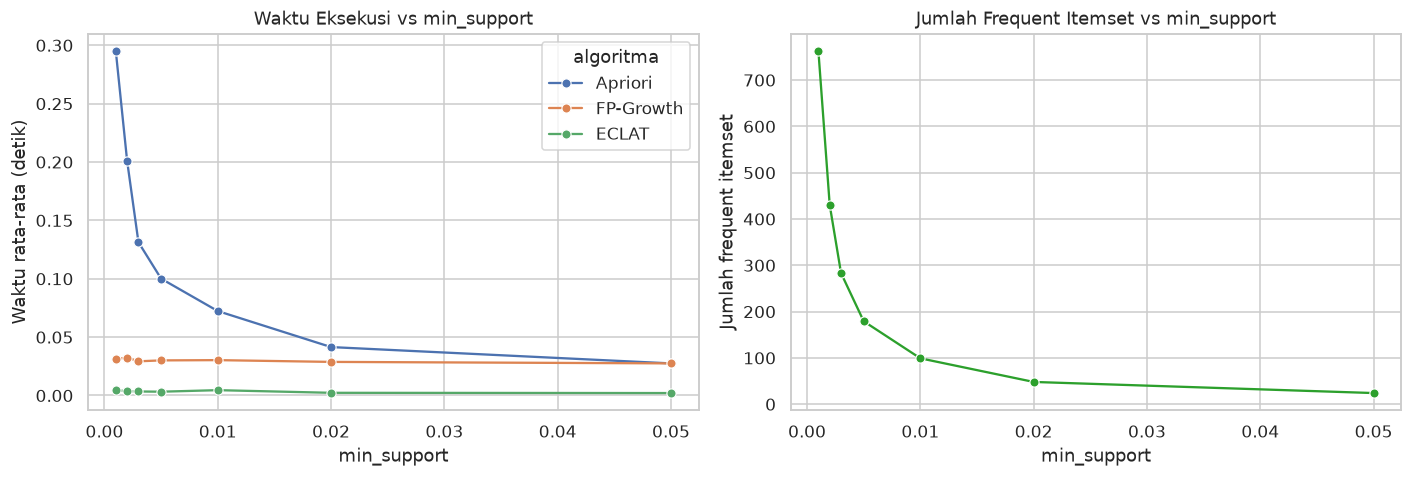

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

t = df_results.drop_duplicates(["algoritma", "min_support"])
sns.lineplot(data=t, x="min_support", y="waktu_detik", hue="algoritma", hue_order=ALGO_ORDER, marker="o", ax=axes[0])
axes[0].set_title("Waktu Eksekusi vs min_support")
axes[0].set_ylabel("Waktu rata-rata (detik)")
axes[0].set_xlabel("min_support")

t_item = t[t["algoritma"] == "Apriori"]
sns.lineplot(data=t_item, x="min_support", y="n_itemset", marker="o", color="tab:green", ax=axes[1])
axes[1].set_title("Jumlah Frequent Itemset vs min_support")
axes[1].set_ylabel("Jumlah frequent itemset")
axes[1].set_xlabel("min_support")

plt.tight_layout()
plt.show()

**Catatan membaca hasil waktu.** Karena ketiga algoritma sama-sama diimplementasikan *from scratch* dengan Python murni, perbandingan waktunya mencerminkan perbedaan kompleksitas algoritmanya secara langsung:
- **Apriori** paling lambat karena harus membangkitkan kandidat di tiap level `k` dan memindai ulang seluruh 5.495 transaksi setiap level (terutama terasa saat `min_support` rendah).
- **FP-Growth** jauh lebih cepat daripada Apriori karena memadatkan transaksi ke dalam struktur FP-Tree tanpa membangkitkan kandidat.
- **ECLAT** menjadi yang tercepat pada dataset ini (5.495 transaksi × 81 item) karena representasi vertikal *TID-set* membuat operasi irisan himpunan (`tids & next_tids`) sangat ringkas dan cepat mengecil.

### 6.3 Jumlah aturan per kombinasi parameter

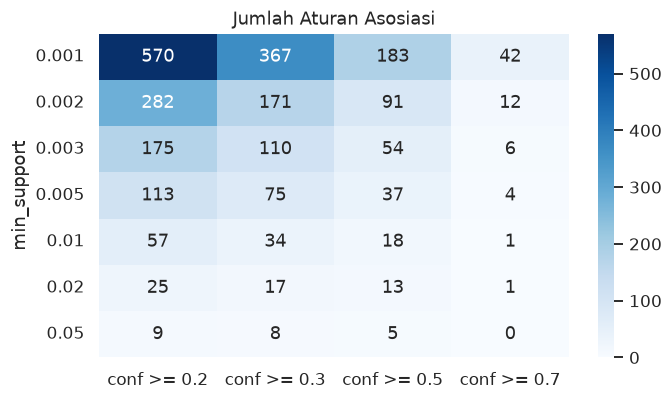

Jumlah aturan Apriori == FP-Growth == ECLAT di semua kombinasi: True


In [18]:
rules_count = (
    df_results[df_results["algoritma"] == "FP-Growth"]
    .pivot(index="min_support", columns="min_confidence", values="n_aturan")
)
rules_count.columns = [f"conf >= {c}" for c in rules_count.columns]

fig, ax = plt.subplots(figsize=(6.5, 3.8))
sns.heatmap(rules_count, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title("Jumlah Aturan Asosiasi")
ax.set_ylabel("min_support")
plt.tight_layout()
plt.show()

# Pastikan jumlah aturan ketiga algoritma sama
same_rules = (
    df_results.pivot_table(index=["min_support", "min_confidence"], columns="algoritma", values="n_aturan")
    .assign(sama=lambda d: (d["Apriori"] == d["FP-Growth"]) & (d["FP-Growth"] == d["ECLAT"]))
)
print("Jumlah aturan Apriori == FP-Growth == ECLAT di semua kombinasi:", bool(same_rules["sama"].all()))

### 6.4 Aturan terbaik berdasarkan *lift*

Confidence saja bisa menyesatkan: item yang sangat populer (misalnya Coffee) akan tampak "terkait" dengan banyak hal hanya karena sering dibeli. **Lift** mengoreksi hal ini dengan membandingkan terhadap peluang kebetulan.

Parameter utama untuk analisis: `min_support = 0.005`, `min_confidence = 0.2` (bisa diubah di sel di bawah). Nilainya sengaja rendah karena dataset ini didominasi Coffee dan Bread, sehingga aturan dengan lift > 1 umumnya berasal dari item yang tidak terlalu populer.

In [19]:
BEST_SUPPORT = 0.005
BEST_CONF = 0.2

freq_best = fpgrowth(basket, min_support=BEST_SUPPORT, use_colnames=True)
rules = make_rules(freq_best, min_threshold=BEST_CONF)

def fmt_set(s):
    return ", ".join(sorted(s))

rules["antecedents_str"] = rules["antecedents"].apply(fmt_set)
rules["consequents_str"] = rules["consequents"].apply(fmt_set)
rules["rule"] = "{" + rules["antecedents_str"] + "} → {" + rules["consequents_str"] + "}"

cols = ["rule", "support", "confidence", "lift"]
print(f"Total aturan (support >= {BEST_SUPPORT}, confidence >= {BEST_CONF}): {len(rules)}")
print(f"Aturan dengan lift > 1: {(rules['lift'] > 1).sum()}")

top_lift = rules.sort_values(["lift", "confidence"], ascending=False).head(10)[cols].reset_index(drop=True)
top_lift.round(3)

Total aturan (support >= 0.005, confidence >= 0.2): 113
Aturan dengan lift > 1: 33


,rule,support,confidence,lift
0,{Coke} → {Sandwich},0.009,0.360,3.230
1,{Mineral water} → {Sandwich},0.006,0.267,2.396
2,"{Coffee, Soup} → {Sandwich}",0.006,0.227,2.032
3,{Truffles} → {Sandwich},0.007,0.206,1.844
4,{Jammie dodgers} → {Cake},0.005,0.246,1.528
5,{Soup} → {Tea},0.016,0.301,1.443
6,"{Coffee, Hot chocolate} → {Cake}",0.012,0.232,1.443
7,{Hot chocolate} → {Cake},0.020,0.224,1.390
8,{Extra salami or feta} → {Coffee},0.006,0.838,1.382
9,{Chicken stew} → {Tea},0.005,0.286,1.371


In [20]:
# Bandingkan: top berdasarkan confidence vs top berdasarkan lift
top_conf = rules.sort_values(["confidence", "lift"], ascending=False).head(10)[cols].reset_index(drop=True)
print("Top 10 berdasarkan CONFIDENCE:")
display(top_conf.round(3))
print("Top 10 berdasarkan LIFT:")
display(top_lift.round(3))

Top 10 berdasarkan CONFIDENCE:


,rule,support,confidence,lift
0,{Extra salami or feta} → {Coffee},0.006,0.838,1.382
1,{Keeping it local} → {Coffee},0.009,0.810,1.335
2,{Toast} → {Coffee},0.041,0.737,1.216
3,{Tartine} → {Coffee},0.005,0.707,1.167
4,{Salad} → {Coffee},0.011,0.681,1.124
5,"{Cake, Sandwich} → {Coffee}",0.008,0.677,1.117
6,"{Hot chocolate, Pastry} → {Coffee}",0.007,0.667,1.100
7,"{Sandwich, Soup} → {Coffee}",0.006,0.654,1.079
8,"{Hot chocolate, Medialuna} → {Coffee}",0.005,0.644,1.063
9,{Medialuna} → {Coffee},0.061,0.631,1.040


Top 10 berdasarkan LIFT:


,rule,support,confidence,lift
0,{Coke} → {Sandwich},0.009,0.360,3.230
1,{Mineral water} → {Sandwich},0.006,0.267,2.396
2,"{Coffee, Soup} → {Sandwich}",0.006,0.227,2.032
3,{Truffles} → {Sandwich},0.007,0.206,1.844
4,{Jammie dodgers} → {Cake},0.005,0.246,1.528
5,{Soup} → {Tea},0.016,0.301,1.443
6,"{Coffee, Hot chocolate} → {Cake}",0.012,0.232,1.443
7,{Hot chocolate} → {Cake},0.020,0.224,1.390
8,{Extra salami or feta} → {Coffee},0.006,0.838,1.382
9,{Chicken stew} → {Tea},0.005,0.286,1.371


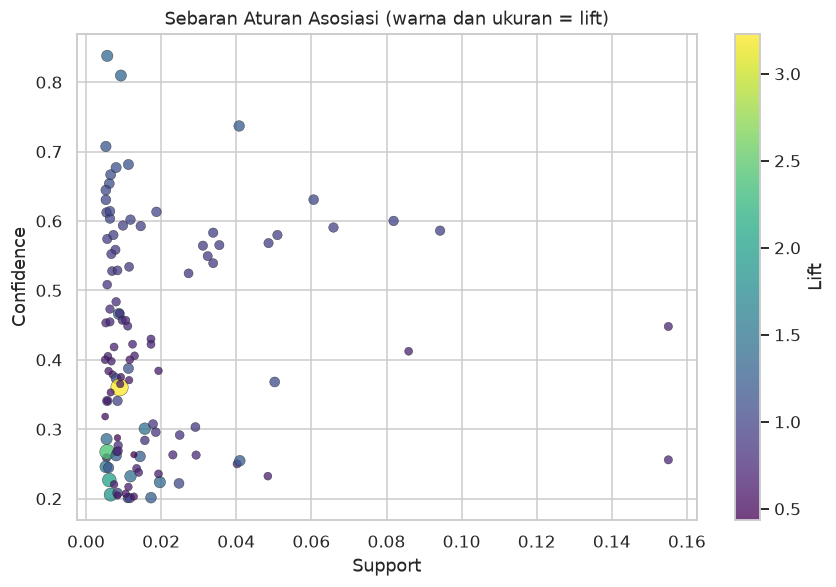

In [21]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sc = ax.scatter(rules["support"], rules["confidence"], c=rules["lift"], s=rules["lift"] * 40,
                cmap="viridis", alpha=0.75, edgecolor="k", linewidth=0.3)
plt.colorbar(sc, label="Lift")
ax.set_xlabel("Support")
ax.set_ylabel("Confidence")
ax.set_title("Sebaran Aturan Asosiasi (warna dan ukuran = lift)")
plt.tight_layout()
plt.show()

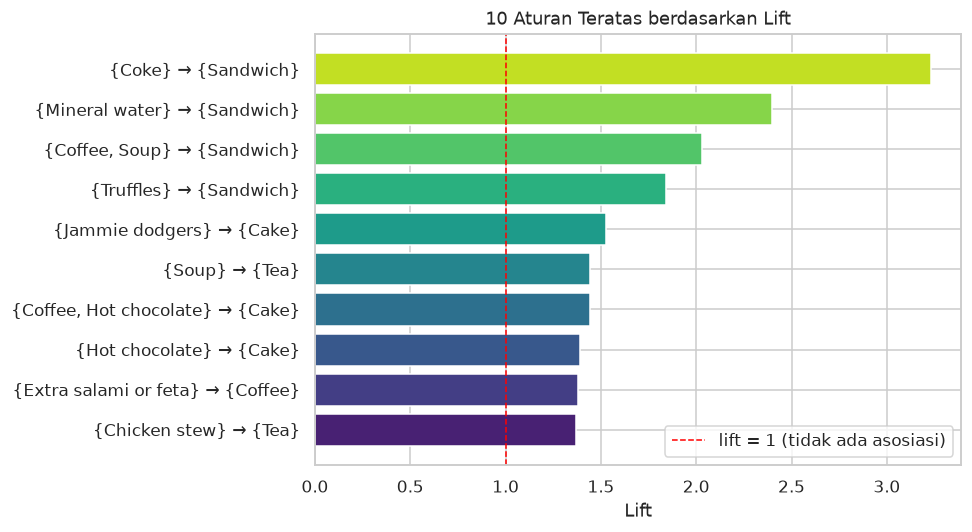

In [22]:
# Visualisasi 10 aturan teratas (berdasarkan lift)
plot_df = top_lift.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(plot_df["rule"], plot_df["lift"], color=sns.color_palette("viridis", len(plot_df)))
ax.axvline(1, color="red", linestyle="--", linewidth=1, label="lift = 1 (tidak ada asosiasi)")
ax.set_xlabel("Lift")
ax.set_title("10 Aturan Teratas berdasarkan Lift")
ax.legend()
plt.tight_layout()
plt.show()

### 6.5 Rekomendasi bundling

Aturan dipilih sebagai kandidat bundling jika memenuhi **lift > 1**, `confidence` cukup tinggi, dan `support` tidak terlalu kecil (agar pola bukan kebetulan pada segelintir transaksi). Aturan dua arah (`A → B` dan `B → A`) diringkas menjadi satu pasangan.

In [23]:
# Kandidat bundling: pasangan 1 item -> 1 item
pairs = rules[(rules["antecedents"].apply(len) == 1) & (rules["consequents"].apply(len) == 1)].copy()
pairs = pairs[(pairs["lift"] > 1.0)]
pairs["pair"] = pairs.apply(lambda r: " + ".join(sorted(list(r["antecedents"]) + list(r["consequents"]))), axis=1)

bundling = (
    pairs.sort_values("lift", ascending=False)
    .drop_duplicates("pair")
    [["pair", "support", "confidence", "lift"]]
    .head(10)
    .reset_index(drop=True)
)
bundling.round(3)

,pair,support,confidence,lift
0,Coke + Sandwich,0.009,0.360,3.230
1,Mineral water + Sandwich,0.006,0.267,2.396
2,Sandwich + Truffles,0.007,0.206,1.844
3,Cake + Jammie dodgers,0.005,0.246,1.528
4,Soup + Tea,0.016,0.301,1.443
5,Cake + Hot chocolate,0.020,0.224,1.390
6,Coffee + Extra salami or feta,0.006,0.838,1.382
7,Chicken stew + Tea,0.005,0.286,1.371
8,Bread + Jam,0.009,0.466,1.346
9,Coffee + Keeping it local,0.009,0.810,1.335


### 6.6 Kesimpulan perbandingan algoritma

Ringkasan otomatis berdasarkan hasil eksperimen di atas:

In [24]:
t = df_results.drop_duplicates(["algoritma", "min_support"]).pivot(
    index="min_support", columns="algoritma", values="waktu_detik"
)[ALGO_ORDER]
t["tercepat"] = t[ALGO_ORDER].idxmin(axis=1)
display(t.round(5))

for algo in ALGO_ORDER:
    wins = (t["tercepat"] == algo).sum()
    print(f"{algo:10s} tercepat pada {wins} dari {len(t)} nilai min_support.")

identik_semua = all(
    {frozenset(s) for s in store[("apriori", ms)]["itemsets"]}
    == {frozenset(s) for s in store[("fpgrowth", ms)]["itemsets"]}
    == {frozenset(s) for s in store[("eclat", ms)]["itemsets"]}
    for ms in SUPPORTS
)
print("Frequent itemset ketiga algoritma identik di semua min_support:", identik_semua)

algoritma,Apriori,FP-Growth,ECLAT,tercepat
min_support,,,,
0.001,0.29517,0.03117,0.00465,ECLAT
0.002,0.20093,0.03253,0.00365,ECLAT
0.003,0.13124,0.02926,0.00343,ECLAT
0.005,0.10006,0.03005,0.00324,ECLAT
0.010,0.07231,0.03028,0.00456,ECLAT
0.020,0.04146,0.02876,0.00229,ECLAT
0.050,0.02747,0.02749,0.00208,ECLAT


Apriori    tercepat pada 0 dari 7 nilai min_support.
FP-Growth  tercepat pada 0 dari 7 nilai min_support.
ECLAT      tercepat pada 7 dari 7 nilai min_support.
Frequent itemset ketiga algoritma identik di semua min_support: True


## 7. Persiapan Deployment (untuk Dashboard Web HTML/CSS/JS)

Aturan yang sudah dihasilkan disimpan ke `association_rules.csv` dan `dashboard/data.js` agar dashboard web di folder `dashboard/` dapat memuatnya langsung (baik melalui server lokal maupun saat dibuka langsung via browser) tanpa menjalankan ulang mining. Disertakan juga fungsi rekomendasi `recommend()` ("pelanggan membeli X, maka rekomendasikan Y") yang diimplementasikan ulang pada dashboard.

In [25]:
import json
from pathlib import Path

# Untuk dashboard, gunakan ambang confidence lebih rendah agar lebih banyak item punya rekomendasi.
DASH_CONF = 0.1
rules_dash = make_rules(freq_best, min_threshold=DASH_CONF)
rules_dash["antecedents_str"] = rules_dash["antecedents"].apply(fmt_set)
rules_dash["consequents_str"] = rules_dash["consequents"].apply(fmt_set)
print(f"Aturan untuk dashboard (support >= {BEST_SUPPORT}, confidence >= {DASH_CONF}): {len(rules_dash)}")

export = rules_dash[["antecedents_str", "consequents_str", "support", "confidence", "lift"]].copy()
export = export.rename(columns={"antecedents_str": "antecedents", "consequents_str": "consequents"})
export = export.sort_values("lift", ascending=False).reset_index(drop=True)
export.to_csv("association_rules.csv", index=False)

# Simpan juga data.js untuk dashboard HTML/CSS/JS agar bisa dibuka langsung tanpa server
dash_dir = Path("dashboard")
if dash_dir.exists():
    with open(dash_dir / "data.js", "w", encoding="utf-8") as f:
        f.write("// Generated from association_rules.csv agar dashboard dapat dibuka langsung tanpa server\n")
        f.write("window.EMBEDDED_RULES = ")
        json.dump(export.to_dict(orient="records"), f, ensure_ascii=False)
        f.write(";\n")

# Simpan juga basket bersih (opsional, untuk mining ulang dengan parameter pilihan)
basket.astype(int).to_csv("basket_onehot.csv")
print("Tersimpan: association_rules.csv, basket_onehot.csv, dan dashboard/data.js")
export.head()

Aturan untuk dashboard (support >= 0.005, confidence >= 0.1): 200
Tersimpan: association_rules.csv, basket_onehot.csv, dan dashboard/data.js


,antecedents,consequents,support,confidence,lift
0,Coke,Sandwich,0.008917,0.360294,3.229716
1,Mineral water,Sandwich,0.005641,0.267241,2.395581
2,"Coffee, Juice",Cookies,0.006369,0.179487,2.098472
3,"Coffee, Cookies",Juice,0.006369,0.131086,2.087879
4,Juice,"Coffee, Cookies",0.006369,0.101449,2.087879


In [26]:
import re

def recommend(items_in_cart, rules_df=export, top_k=5, min_lift=1.0):
    """Rekomendasikan item berdasarkan isi keranjang.

    items_in_cart : list nama item, misalnya ["Coffee"] atau ["Bread", "Coffee"]
    Aturan dipakai jika seluruh antecedent ada di dalam keranjang.
    """
    cart = {re.sub(r"\s+", " ", i.strip()).lower().capitalize() for i in items_in_cart}
    out = []
    for _, r in rules_df.iterrows():
        ante = set(r["antecedents"].split(", "))
        cons = set(r["consequents"].split(", "))
        if ante.issubset(cart) and not cons.issubset(cart) and r["lift"] >= min_lift:
            out.append({
                "rekomendasi": ", ".join(sorted(cons - cart)),
                "karena_membeli": r["antecedents"],
                "confidence": r["confidence"],
                "lift": r["lift"],
            })
    if not out:
        return pd.DataFrame(columns=["rekomendasi", "karena_membeli", "confidence", "lift"])
    res = pd.DataFrame(out).sort_values(["lift", "confidence"], ascending=False)
    return res.drop_duplicates("rekomendasi").head(top_k).reset_index(drop=True)

recommend(["Juice"])

,rekomendasi,karena_membeli,confidence,lift
0,"Coffee, Cookies",Juice,0.101449,2.087879
1,Cookies,Juice,0.168116,1.965526
2,Sandwich,Juice,0.159420,1.429061
3,Cake,Juice,0.194203,1.207178
4,"Cake, Coffee",Juice,0.107246,1.137681


In [27]:
recommend(["Soup"])

,rekomendasi,karena_membeli,confidence,lift
0,"Coffee, Sandwich",Soup,0.118881,1.804563
1,Sandwich,Soup,0.181818,1.629838
2,Tea,Soup,0.300699,1.443094


In [28]:
# Item yang sangat populer (Coffee, Bread) tidak punya aturan dengan lift > 1 sebagai antecedent,
# karena pembeliannya hampir tidak bergantung pada item lain. Hasil kosong di bawah memang wajar.
recommend(["Coffee"])

,rekomendasi,karena_membeli,confidence,lift


## 8. Ringkasan untuk Presentasi

Ringkasan hasil analisis berdasarkan output eksperimen di atas:

- **Item terlaris (4a):** Coffee (4.528 transaksi), Bread (3.097), Tea (1.350), Cake (983), dan Pastry (815).
- **Waktu puncak transaksi (4c & 4d):** Jam ramai berada di pukul 10.00–12.00 dengan puncak pukul 11.00 (1.435 transaksi). Hari tersibuk adalah Sabtu (2.035 transaksi) diikuti Jumat (1.473). Berdasarkan periode, transaksi terbanyak terjadi pada siang/*afternoon* (5.083) dan pagi/*morning* (4.093).
- **Perbandingan algoritma *from scratch* (Apriori vs FP-Growth vs ECLAT — 6.1, 6.2, 6.6):** Ketiga algoritma diimplementasikan tanpa library mining (`mlxtend`) dan menghasilkan *frequent itemset* serta jumlah aturan **100% identik** di seluruh 7 nilai `min_support` dan 4 nilai `min_confidence`. **ECLAT** tercepat pada **7 dari 7** nilai `min_support` (pada `min_support=0.001`: `0.00465` dtk), diikuti **FP-Growth** (`0.03117` dtk, ~9,5× lebih cepat dari Apriori), dan **Apriori** paling lambat (`0.29517` dtk) karena pemindaian transaksi berulang per level kandidat.
- **Aturan dengan lift tertinggi (`min_support=0.005`, `min_confidence=0.2` — 6.4):** `{Coke} → {Sandwich}` (lift `3.230`, conf `36.0%`), `{Mineral water} → {Sandwich}` (lift `2.396`, conf `26.7%`), `{Coffee, Soup} → {Sandwich}` (lift `2.032`, conf `22.7%`), `{Truffles} → {Sandwich}` (lift `1.844`, conf `20.6%`), dan `{Jammie dodgers} → {Cake}` (lift `1.528`, conf `24.6%`).
- **Rekomendasi bundling untuk toko (6.5):** Paket makan siang (`Coke + Sandwich`, `Mineral water + Sandwich`, `Soup + Tea`), paket camilan/kue (`Cake + Hot chocolate`, `Cake + Jammie dodgers`, `Sandwich + Truffles`), serta paket sarapan (`Bread + Jam`).
- **Deployment (7):** Dashboard interaktif berbasis HTML, CSS, dan JavaScript tersedia di folder `dashboard/index.html` dengan simulasi kasir (etalase berkategori + slip saran upsell), daftar paket bundling, eksplorasi aturan, dan benchmark algoritma.
- **Keterbatasan:** Data hanya berasal dari satu toko (Oktober 2016 – April 2017), tidak memiliki informasi harga atau kuantitas pembelian, transaksi 1 item (41,7%) dibuang untuk proses mining, dan asosiasi menunjukkan keterkaitan pembelian bukan hubungan sebab-akibat.